# BDB 2027 — Defensive back types, injury, and the short shuttle

This notebook asks the same questions as the OL work, from the defensive back side:

1. **What kinds of DBs are there?** It builds two **independent** typologies:
   - **Tracking types**: how a DB actually plays (alignment, depth, coverage role, speed and closing behavior), clustered from game tracking.
   - **Combine types**: what kind of athlete he tested as (size, speed, agility, explosiveness), clustered from Combine results.

   They're built from disjoint inputs, so a "deep safety" in one can be any Combine type in the other. The notebook measures how much they overlap.
2. **Do those types carry different injury risk or cost?** It looks at injury onsets (public injury reports), lower-body and hamstring injuries, absences, snaps, coverage performance, and **speed in coverage before vs. after injury**.
3. **The short shuttle, in depth.** The Combine sensor data tracks the 5-10-5 itself. That means it can be split into legs, **turns**, braking into each turn, re-acceleration, **turn-to-turn asymmetry**, and a **change-of-direction (COD) deficit** (shuttle time minus a straight 20 yards). Each piece is tested against injury and speed outcomes.
4. **What should scouts test?** The last section maps the injury tendencies found here to concrete Combine drill proposals, and flags which ones this run's evidence supports.

Everything is descriptive, with intervals. Draft pick is controlled wherever it could confound.

**Needs:** `statsmodels`, and internet on the first run (nflverse injury reports, cached in `external/`). The first run also scans the game tracking files for DBs and caches per-rep features.

## 0. Setup

In [1]:
from pathlib import Path
import re as _re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import patsy
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="An input array is constant")
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.max_columns", 120); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [Path("data"), Path("../data"), Path("data/raw"), Path("/kaggle/input/nfl-big-data-bowl-2027")]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())
EXT_DIR = Path("external"); EXT_DIR.mkdir(exist_ok=True)
NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists(): raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

# ---- knobs ---------------------------------------------------------------
SEASONS        = [2023, 2024, 2025]
REGULAR_SNAPS  = 20
EXIT_FRAC      = 0.5
LONG_ABSENCE   = 4
WIN_S          = 6.0      # seconds after the snap kept per rep (covers the pass phase)
HS_SPEED       = 7.0      # yd/s (~14.3 mph) high-speed threshold
MIN_REPS_TYPE  = 150      # reps needed for a player to get a tracking type
K_TRK, K_CMB   = 5, 4     # number of tracking types / Combine types (sweeps shown to check)
BASE_K, BASE_MIN = 6, 3
N_BOOT         = 1000
RNG            = np.random.default_rng(27)
REP_CACHE      = Path("db_rep_features.parquet")
NFLVERSE       = "https://github.com/nflverse/nflverse-data/releases/download"
SNAP           = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
ARRIVE         = {"pass_arrived", "pass_outcome_caught", "pass_outcome_incomplete", "pass_outcome_interception"}
# --------------------------------------------------------------------------

def cluster_boot_mean(values, clusters, n=N_BOOT):
    d = pd.DataFrame({"v": values, "c": clusters}).dropna()
    if d.empty: return np.nan, np.nan, np.nan, 0
    agg = d.groupby("c")["v"].agg(["sum", "size"]); k = len(agg)
    if k < 3: return d["v"].mean(), np.nan, np.nan, len(d)
    draws = RNG.integers(0, k, (n, k)); s, c = agg["sum"].to_numpy(), agg["size"].to_numpy()
    return d["v"].mean(), *np.percentile(s[draws].sum(1) / c[draws].sum(1), [2.5, 97.5]), len(d)

def poisson_rate(e, x, per=100):
    if x <= 0: return np.nan, np.nan, np.nan
    lo = stats.chi2.ppf(.025, 2 * e) / 2 if e > 0 else 0.0
    hi = stats.chi2.ppf(.975, 2 * (e + 1)) / 2
    return per * e / x, per * lo / x, per * hi / x

def zs(s): return (s - s.mean()) / s.std()

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


In [2]:
# Robust mixed model helper (drops collinear columns, tries several optimizers, falls back to within-player OLS)
results = {}
def _var(t):
    m_ = _re.match(r"C\(([^,)]+)", t); return m_.group(1).strip() if m_ else t
def _ok(d, v): return v in d and d[v].nunique(dropna=True) > 1
def _design(y, terms, d):
    Y, X = patsy.dmatrices(f"{y} ~ " + (" + ".join(terms) if terms else "1"), d, return_type="dataframe")
    kept = []
    for c in X.columns:
        if np.linalg.matrix_rank(X[kept + [c]].to_numpy()) > len(kept): kept.append(c)
    return Y.iloc[:, 0], X[kept], [c for c in X.columns if c not in kept]

def fit(y, terms, data, name, group="nfl_id", show=True):
    need = {y, group} | {_var(p) for t in terms for p in _re.split(r"[*:]", t)}
    d = data.dropna(subset=[c for c in need if c in data]).copy()
    terms = [t for t in terms if all(_ok(d, _var(p)) for p in _re.split(r"[*:]", t))]
    if len(d) < 30: print(f"{name}: too few rows ({len(d)})"); return None
    Y, X, dropped = _design(y, terms, d); groups = d.loc[X.index, group]
    r, how = None, None
    for reml in (True, False):
        for method in ("lbfgs", "powell", "bfgs"):
            try:
                r = sm.MixedLM(Y, X, groups=groups).fit(method=method, reml=reml); how = f"MixedLM ({method})"; break
            except Exception: continue
        if r is not None: break
    if r is None:
        Xw = X.drop(columns=["Intercept"], errors="ignore")
        r = sm.OLS(Y - Y.groupby(groups).transform("mean"), Xw - Xw.groupby(groups).transform("mean")).fit(
            cov_type="cluster", cov_kwds={"groups": groups}); how = "within-player OLS (clustered)"
    results[name] = r
    if show:
        ci = r.conf_int()
        tab = pd.DataFrame({"coef": r.params, "ci_lo": ci[0], "ci_hi": ci[1], "p": r.pvalues}).drop(index="Group Var", errors="ignore")
        print(f"\n{name} | {how} | n={len(Y):,}, players={groups.nunique()}" + (f" | dropped: {dropped}" if dropped else ""))
        display(tab.round(3))
    return r

## 1. DB cohort and play context

In [3]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
PICK = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
DB_LABELS = {"CB", "S", "FS", "SS", "DB", "SAF", "NB"}
pos_src = prof[NFL_POS].astype(str).str.upper() if NFL_POS else pd.Series("", index=prof.index)
cmb_src = prof[CMB_POS].astype(str).str.upper() if CMB_POS else pd.Series("", index=prof.index)
db = prof[pos_src.isin(DB_LABELS) | cmb_src.isin(DB_LABELS)].copy()
db["listed_role"] = np.where(pos_src[db.index].isin({"S", "FS", "SS", "SAF"}) | cmb_src[db.index].isin({"S", "FS", "SS", "SAF"}), "S", "CB")
db["log_pick"] = np.log(db[PICK].fillna(db[PICK].max() + 32)) if PICK else 0.0
DB_IDS = set(db["nfl_id"])
print(f"DBs in cohort: {len(db)} |", db["listed_role"].value_counts().to_dict())

TEAM = pick(pp, ["team_abbr", "club", "team"], required=True)
LUP  = pick(pp, ["lined_up_position", "position_at_snap"])
DIR, QTR = pick(pp, ["play_direction"]), pick(pp, ["quarter"])
POSS = pick(pp, ["possession_team"]); YLS = pick(pp, ["yardline_side"]); YLN = pick(pp, ["yardline_number"])
COV_A = pick(pp, ["coverage_assignment", "pff_defensive_coverage_assignment"])
COV_T = pick(pp, ["team_coverage_type", "pff_pass_coverage", "team_coverage_man_zone", "pff_man_zone"])
EPA = pick(pp, ["expected_points_added", "epa"])
TCK = pick(pp, ["tackle", "solo_tackle", "tackles"])
PBU = pick(pp, ["pass_defensed", "pass_breakup", "pass_deflection"])
DROP = pick(pp, ["is_dropback"]); PRES = pick(pp, ["pass_result"])
HOME, AWAY = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
GDATE = pick(games, ["game_date", "date", "gameday"])
print(dict(LUP=LUP, COV_A=COV_A, COV_T=COV_T, EPA=EPA, TCK=TCK, PBU=PBU, LOS_cols=(POSS, YLS, YLN, DIR)))

gcols = ["game_id", "season", "week"] + [c for c in ["season_type"] if c in games]
cp = pp[pp["nfl_id"].isin(DB_IDS)].merge(games[gcols], on="game_id", how="left")
if "season_type" in cp: cp = cp[cp["season_type"].fillna("REG") == "REG"]
if DROP: cp["is_pass"] = cp[DROP].astype(str).str.lower().isin(["true", "1"])
elif PRES: cp["is_pass"] = cp[PRES].notna()
else: cp["is_pass"] = True

# Line of scrimmage (absolute x) for alignment depth
if all([POSS, YLS, YLN, DIR]):
    own = cp[YLS] == cp[POSS]
    right = cp[DIR] == "right"
    cp["los_x"] = np.select([right & own, right & ~own, ~right & own], [10 + cp[YLN], 110 - cp[YLN], 110 - cp[YLN]], 10 + cp[YLN])
else:
    cp["los_x"] = np.nan; print("LOS columns missing — alignment depth will be unavailable")
cp["sgn"] = np.where(cp[DIR] == "left", -1, 1) if DIR else 1

up = cp[LUP].astype(str).str.upper() if LUP else pd.Series("", index=cp.index)
cp["align"] = np.select([up.str.contains("SLOT|NICKEL|NB"), up.str.contains("FS|SS|SAF|^S$", regex=True), up.str.contains("CB")],
                        ["slot", "safety", "outside CB"], "other")
if LUP: print("lined_up_position values (DB rows):", up.value_counts().head(12).to_dict())
a = cp[COV_A].astype(str).str.upper() if COV_A else pd.Series("", index=cp.index)
t = cp[COV_T].astype(str).str.upper() if COV_T else pd.Series("", index=cp.index)
DEEP_CODES = {"2L", "2R", "3L", "3M", "3R", "4IL", "4IR", "4OL", "4OR", "DF"}
cp["is_man"] = a.str.contains("MAN|PRE") | t.str.contains("MAN")
cp["is_deep"] = a.isin(DEEP_CODES) | a.str.contains("DEEP|HALF|QUARTER|THIRD")
if COV_A: print("coverage_assignment values:", a.value_counts().head(12).to_dict())

DBs in cohort: 122 | {'CB': 69, 'S': 53}
{'LUP': 'lined_up_position', 'COV_A': 'coverage_assignment', 'COV_T': 'team_coverage_type', 'EPA': 'expected_points_added', 'TCK': 'tackle', 'PBU': None, 'LOS_cols': ('possession_team', 'yardline_side', 'yardline_number', 'play_direction')}
lined_up_position values (DB rows): {'CB': 28653, 'HIGH_SAFETY': 19337, 'SLOT_CB': 11190, 'OLB': 4917, 'MLB': 1251, 'EDGE': 1170, 'BOX_SAFETY': 222, 'INTERIOR_LINE': 110, 'NAN': 39, 'RB': 19, 'FB': 5, 'WR': 1}
coverage_assignment values: {'NAN': 27335, 'MAN': 10076, 'DEEP_THIRD_RIGHT': 2765, 'CURL_FLAT_LEFT': 2498, 'DEEP_THIRD_MIDDLE': 2486, 'CURL_FLAT_RIGHT': 2231, 'DEEP_THIRD_LEFT': 1982, 'QUARTERS_OUTSIDE_RIGHT': 1935, 'QUARTERS_INSIDE_LEFT': 1865, 'QUARTERS_INSIDE_RIGHT': 1636, 'FLAT_RIGHT': 1614, 'DEEP_HALF_LEFT': 1531}


## 2. Injury labels (nflverse) and the DB player-game panel

This is the same join as the get-off notebook: nflverse `nfl_id` matches BDB `nfl_id`. Hamstring is also flagged separately, because it's the signature soft-tissue injury for players who sprint at high speed.

In [4]:
def nflverse_csv(tag, fname):
    local = EXT_DIR / fname
    if not local.exists():
        print("downloading", f"{NFLVERSE}/{tag}/{fname}")
        pd.read_csv(f"{NFLVERSE}/{tag}/{fname}", low_memory=False).to_csv(local, index=False)
    return pd.read_csv(local, low_memory=False)

idmap = nflverse_csv("players", "players.csv").dropna(subset=["nfl_id"])[["gsis_id", "nfl_id"]].astype({"nfl_id": "int64"}).drop_duplicates("gsis_id")
inj = pd.concat([nflverse_csv("injuries", f"injuries_{y}.csv") for y in SEASONS], ignore_index=True)
inj = inj[inj["game_type"] == "REG"]
if "date_modified" in inj: inj = inj.sort_values("date_modified")
inj = inj.drop_duplicates(["season", "week", "gsis_id"], keep="last").merge(idmap, on="gsis_id")
inj = inj[inj["nfl_id"].isin(DB_IDS)].copy()
body = inj["report_primary_injury"].fillna(inj.get("practice_primary_injury")).astype(str).str.lower()
LOWER = ["knee", "ankle", "foot", "hamstring", "calf", "hip", "groin", "achilles", "quad", "toe", "thigh", "shin", "leg", "heel", "fibula", "tibia"]
NON = ["not injury", "rest", "illness", "personal", "coach", "nan"]
inj["is_injury"] = ~body.apply(lambda s: any(k in s for k in NON))
inj["lower"] = inj["is_injury"] & body.apply(lambda s: any(k in s for k in LOWER))
inj["hamstring"] = inj["is_injury"] & body.str.contains("hamstring")
inj["status"] = inj["report_status"].fillna("listed")
weekly = inj[["nfl_id", "season", "week", "is_injury", "lower", "hamstring", "status"]]
print(f"DB injury-report rows: {len(weekly):,} | DBs ever listed: {weekly['nfl_id'].nunique()} | hamstring weeks: {int(weekly['hamstring'].sum())}")

sched = pd.concat([games[["game_id", "season", "week", HOME]].rename(columns={HOME: "team"}),
                   games[["game_id", "season", "week", AWAY]].rename(columns={AWAY: "team"})])
if "season_type" in games: sched = sched[sched["game_id"].isin(games.loc[games["season_type"] == "REG", "game_id"])]
sched = sched.sort_values(["team", "season", "week"]); sched["team_game_no"] = sched.groupby(["team", "season"]).cumcount() + 1
pg = cp.groupby(["nfl_id", "game_id", "season", "week"]).agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index()
stint = (pg.merge(sched[["game_id", "team", "team_game_no"]], on=["game_id", "team"])
           .groupby(["nfl_id", "season", "team"])["team_game_no"].agg(first_g="min", last_g="max").reset_index())
stint["multi"] = stint.groupby(["nfl_id", "season"])["team"].transform("nunique") > 1
panel = stint.merge(sched, on=["season", "team"])
panel = panel[(panel["team_game_no"] >= panel["first_g"]) & ((panel["team_game_no"] <= panel["last_g"]) | ~panel["multi"])]
panel = panel.merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left").fillna({"snaps": 0})
panel = panel.merge(weekly, on=["nfl_id", "season", "week"], how="left")
for c in ["is_injury", "lower", "hamstring"]: panel[c] = panel[c].fillna(False).astype(bool)
panel = panel.sort_values(["nfl_id", "season", "team", "team_game_no"]).reset_index(drop=True)
G = panel.groupby(["nfl_id", "season", "team"])
panel["played"] = panel["snaps"] > 0
panel["established"] = G["snaps"].transform(lambda s: (s >= REGULAR_SNAPS).shift(fill_value=False).cummax())
panel["prev_played"] = G["played"].shift(fill_value=False)
panel["trail_med"] = G["snaps"].transform(lambda s: s.where(s >= REGULAR_SNAPS).shift().expanding().median())
panel["absence_start"] = panel["established"] & panel["prev_played"] & ~panel["played"]
panel["spell_id"] = (panel["played"] != G["played"].shift()).cumsum()
panel["spell_len"] = panel["spell_id"].map(panel[~panel["played"]].groupby("spell_id").size()).where(panel["absence_start"])
panel["long_absence_start"] = panel["absence_start"] & (panel["spell_len"] >= LONG_ABSENCE)
panel["exit"] = panel["established"] & panel["played"] & panel["trail_med"].notna() & (panel["snaps"] < EXIT_FRAC * panel["trail_med"])
panel["onset"] = panel["is_injury"] & ~G["is_injury"].shift(fill_value=False)
panel["onset_lower"] = panel["onset"] & panel["lower"]
panel["onset_ham"] = panel["onset"] & panel["hamstring"]
print(f"panel {len(panel):,} | onsets {int(panel['onset'].sum())} (lower {int(panel['onset_lower'].sum())}, hamstring {int(panel['onset_ham'].sum())})")

# Player-level outcomes
O = panel.groupby("nfl_id").agg(team_games=("game_id", "size"), games=("played", "sum"), snaps=("snaps", "sum"),
                                onsets=("onset", "sum"), onsets_lower=("onset_lower", "sum"), onsets_ham=("onset_ham", "sum"),
                                absences=("absence_start", "sum"), long_abs=("long_absence_start", "sum"), exits=("exit", "sum"))
O["usage_rate"] = O["games"] / O["team_games"]; O["snaps_per_team_game"] = O["snaps"] / O["team_games"]
perf = cp.groupby("nfl_id").agg(**({"epa_on_field": (EPA, "mean")} if EPA else {}),
                                **({"tackles_per_100": (TCK, lambda s: 100 * pd.to_numeric(s, errors="coerce").fillna(0).mean())} if TCK else {}),
                                **({"pbu_per_100": (PBU, lambda s: 100 * pd.to_numeric(s, errors="coerce").fillna(0).mean())} if PBU else {}))
db = db.drop(columns=[c for c in list(O) + list(perf) if c in db]).merge(O, left_on="nfl_id", right_index=True, how="left").merge(perf, left_on="nfl_id", right_index=True, how="left")

DB injury-report rows: 459 | DBs ever listed: 83 | hamstring weeks: 55


C:\Users\bchm5\AppData\Local\Temp\ipykernel_6320\874145770.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  for c in ["is_injury", "lower", "hamstring"]: panel[c] = panel[c].fillna(False).astype(bool)
C:\Users\bchm5\AppData\Local\Temp\ipykernel_6320\874145770.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  for c in ["is_injury", "lower", "hamstring"]: panel[c] = panel[c].fillna(False).astype(bool)
C:\Users\bchm5\AppData\Local\Temp\ipykernel_6320\874145770.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is depreca

panel 2,411 | onsets 195 (lower 118, hamstring 21)


## 3. Rep features from game tracking (chunked + cached)

For every DB rep (player × play), from the snap through `WIN_S` s:

| feature | meaning |
|---|---|
| `depth_snap` | yards off the line of scrimmage at the snap |
| `width_snap` | yards from the nearest sideline |
| `bail_1s` | depth gained in the first second (+ = bailing or backpedaling, − = triggering downhill) |
| `lat_1s` | lateral yards in the first second |
| `get_off` | time to move 0.5 yd |
| `peak_speed`, `hs_s` | top speed; seconds at ≥ `HS_SPEED` yd/s (high-speed running) |
| `peak_accel`, `peak_decel` | hardest acceleration and braking (yd/s²) |
| `close_speed`, `close_accel` | mean speed and peak acceleration **while the ball is in the air** (pass_forward → arrival). This is the most direct "speed in coverage" measure. |

In [5]:
ctx = cp[["game_id", "play_id", "nfl_id", "los_x", "sgn"]].drop_duplicates(["game_id", "play_id", "nfl_id"])

def rep_feats(f):
    k = ["game_id", "play_id", "nfl_id"]
    f = f.merge(ctx, on=k, how="inner").sort_values(k + ["time"])
    if f.empty: return pd.DataFrame()
    snap = f.loc[f["event"].isin(SNAP)].groupby(k)["time"].min().rename("snap_time")
    f = f.merge(snap, left_on=k, right_index=True)
    f["t"] = (f["time"] - f["snap_time"]).dt.total_seconds()
    f = f[(f["t"] >= 0) & (f["t"] <= WIN_S)]
    if f.empty: return pd.DataFrame()
    g = f.groupby(k); keys = [f[c] for c in k]
    f["depth"] = f["sgn"] * (f["x"] - f["los_x"])
    d0 = g["depth"].transform("first"); x0, y0 = g["x"].transform("first"), g["y"].transform("first")
    f["disp"] = np.hypot(f["x"] - x0, f["y"] - y0)
    dt = g["t"].diff(); f["dv"] = (g["s"].diff() / dt).where(dt <= 0.25)
    f["t_pf"] = f["t"].where(f["event"] == "pass_forward").groupby(keys).transform("min")
    f["t_arr"] = f["t"].where(f["event"].isin(ARRIVE)).groupby(keys).transform("min")
    air = f["t"].between(f["t_pf"], f["t_arr"])
    at1 = f["t"].between(0.95, 1.05)
    out = pd.DataFrame({
        "depth_snap": g["depth"].first(), "width_snap": g["y"].first().pipe(lambda y: np.minimum(y, 53.3 - y)),
        "bail_1s": (f["depth"] - d0).where(at1).groupby(keys).first(),
        "lat_1s": (f["y"] - y0).abs().where(at1).groupby(keys).first(),
        "get_off": f["t"].where(f["disp"] >= 0.5).groupby(keys).min(),
        "peak_speed": g["s"].max(), "hs_s": (f["s"] >= HS_SPEED).groupby(keys).sum() * 0.1,
        "peak_accel": f["dv"].groupby(keys).max(), "peak_decel": (-f["dv"]).groupby(keys).max(),
        "close_speed": f["s"].where(air).groupby(keys).mean(), "close_accel": f["dv"].where(air).groupby(keys).max(),
        "n_frames": g.size()})
    return out[out["n_frames"] >= 15].reset_index()

if REP_CACHE.exists():
    rep = pd.read_parquet(REP_CACHE); print("loaded", REP_CACHE)
else:
    parts, use = [], ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]
    for season in SEASONS:
        carry = None
        for ch in pd.read_csv(find_csv(f"game_tracking_{season}"), usecols=use, chunksize=2_000_000, na_values=NULLS):
            ch = ch[ch["nfl_id"].isin(DB_IDS)]
            ch["time"] = pd.to_datetime(ch["time"], errors="coerce")
            if carry is not None: ch = pd.concat([carry, ch], ignore_index=True)
            if ch.empty: continue
            last = ch["game_id"].iloc[-1]; carry = ch[ch["game_id"] == last]; ch = ch[ch["game_id"] != last]
            if len(ch): parts.append(rep_feats(ch))
        if carry is not None and len(carry): parts.append(rep_feats(carry))
        print(season, "processed")
    rep = pd.concat(parts, ignore_index=True)
    rep = rep[~rep.duplicated(["game_id", "play_id", "nfl_id"], keep=False)]
    rep.to_parquet(REP_CACHE, index=False)

rep = rep.merge(cp[["game_id", "play_id", "nfl_id", "align", "is_man", "is_deep", "is_pass"]], on=["game_id", "play_id", "nfl_id"], how="left")
REPF = ["depth_snap", "width_snap", "bail_1s", "lat_1s", "get_off", "peak_speed", "hs_s", "peak_accel", "peak_decel", "close_speed", "close_accel"]
print(f"DB reps: {len(rep):,} | players: {rep['nfl_id'].nunique()}")
display(rep[REPF].describe(percentiles=[.05, .5, .95]).round(2))

2023 processed
2024 processed
2025 processed
DB reps: 66,875 | players: 96


,depth_snap,width_snap,bail_1s,lat_1s,get_off,peak_speed,hs_s,peak_accel,peak_decel,close_speed,close_accel
count,66875.00,66875.00,66875.00,66875.00,66441.00,66875.00,66875.00,66875.00,66875.00,34011.00,34011.00
mean,6.62,17.90,0.34,0.66,0.81,5.54,0.26,4.72,4.21,4.38,2.52
std,4.65,4.83,1.01,0.80,0.39,1.66,0.64,1.58,1.98,1.84,2.15
min,-12.94,1.20,-5.94,0.00,0.10,0.00,0.00,-1.00,-0.80,0.00,-7.00
5%,0.84,9.44,-1.38,0.03,0.30,2.84,0.00,2.60,1.50,1.58,-1.00
50%,5.92,18.30,0.35,0.41,0.80,5.54,0.00,4.70,4.00,4.27,2.50
95%,14.70,25.22,1.95,2.12,1.50,8.28,1.90,7.10,7.70,7.61,6.10
max,84.62,26.65,5.10,8.09,4.60,13.87,4.40,136.50,83.20,10.08,25.70


## 4. Typology A: tracking types (how he plays)

Player-level profile, using pass plays for the coverage features:
- **alignment shares**: outside CB, slot, safety
- **coverage shares**: man, deep (when coverage columns exist)
- median depth and width at the snap, median first-second bail
- **speed profile**: p90 peak speed, high-speed seconds per rep, p90 braking, median closing speed with the ball in the air

These are standardized and clustered with k-means. A k-sweep shows whether `K_TRK` is reasonable. Types get **automatic names from their centroids** (e.g. *deep safety*, *box safety*, *slot*, *press-man corner*, *off/zone corner*), with a distinguishing trait added when two types share a role.

DBs with ≥150 pass reps: 63 | features: ['share_outside', 'share_slot', 'share_safety', 'share_man', 'share_deep', 'depth', 'width', 'bail', 'speed_p90', 'hs_per_rep', 'brake_p90', 'close_speed', 'get_off']


  File "c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


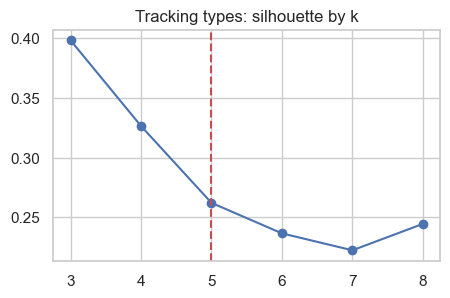

,share_outside,share_slot,share_safety,share_man,share_deep,depth,width,bail,speed_p90,hs_per_rep,brake_p90,close_speed,get_off,n
type,,,,,,,,,,,,,,
deep safety · low close_speed,0.02,0.15,0.71,0.23,0.54,10.78,20.52,0.42,7.62,0.26,6.59,3.93,0.71,12
press-man corner · low width,0.97,0.02,0.00,0.28,0.53,4.90,13.57,0.65,7.92,0.34,7.18,4.49,0.82,10
slot DB,0.07,0.65,0.13,0.32,0.14,4.04,19.39,0.33,7.95,0.35,7.28,4.19,0.78,12
deep safety · high depth,0.01,0.10,0.80,0.28,0.64,11.72,21.31,0.68,7.83,0.31,7.05,4.23,0.63,11
press-man corner · high hs_per_rep,0.89,0.07,0.01,0.39,0.39,4.49,13.43,0.47,8.28,0.47,6.95,4.65,0.91,18


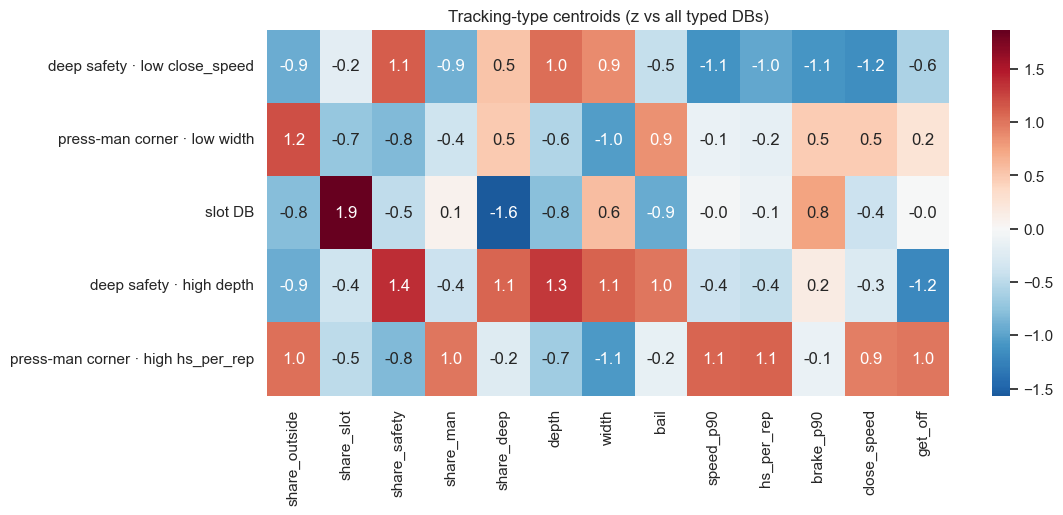

In [6]:
pas = rep[rep["is_pass"] != False]
prof_t = pas.groupby("nfl_id").agg(
    reps=("play_id", "size"),
    share_outside=("align", lambda s: (s == "outside CB").mean()), share_slot=("align", lambda s: (s == "slot").mean()),
    share_safety=("align", lambda s: (s == "safety").mean()),
    share_man=("is_man", "mean"), share_deep=("is_deep", "mean"),
    depth=("depth_snap", "median"), width=("width_snap", "median"), bail=("bail_1s", "median"),
    speed_p90=("peak_speed", lambda s: s.quantile(.9)), hs_per_rep=("hs_s", "mean"),
    brake_p90=("peak_decel", lambda s: s.quantile(.9)), close_speed=("close_speed", "median"), get_off=("get_off", "median"))
prof_t = prof_t[prof_t["reps"] >= MIN_REPS_TYPE]
TF = [c for c in prof_t.columns if c != "reps" and prof_t[c].notna().mean() > .8 and prof_t[c].std() > 0]
Xt = StandardScaler().fit_transform(prof_t[TF].fillna(prof_t[TF].median()))
print(f"DBs with ≥{MIN_REPS_TYPE} pass reps: {len(prof_t)} | features: {TF}")

sw = [(k, silhouette_score(Xt, KMeans(k, n_init=10, random_state=27).fit_predict(Xt))) for k in range(3, 9) if k < len(prof_t)]
plt.figure(figsize=(5, 3)); plt.plot(*zip(*sw), "o-"); plt.axvline(K_TRK, color="r", ls="--"); plt.title("Tracking types: silhouette by k"); plt.show()
km_t = KMeans(K_TRK, n_init=20, random_state=27).fit(Xt)
prof_t["trk_type_id"] = km_t.labels_
cent = prof_t.groupby("trk_type_id")[TF].mean()
cz = (cent - prof_t[TF].mean()) / prof_t[TF].std()

def name_trk(row, z):
    if row.get("share_safety", 0) > .5:
        base = "deep safety" if (row.get("depth", 0) >= 10 or row.get("share_deep", 0) > .5) else "box/rotation safety"
    elif row.get("share_slot", 0) > .35: base = "slot DB"
    else:
        base = "press-man corner" if (row.get("depth", 99) <= 5 or z.get("share_man", 0) > .5) else "off/zone corner"
    return base
names = {i: name_trk(cent.loc[i], cz.loc[i]) for i in cent.index}
dup = pd.Series(names).duplicated(keep=False)
for i in cent.index:
    if dup[i]:
        z = cz.loc[i].drop([c for c in cz.columns if c.startswith("share_")], errors="ignore")
        top = z.abs().idxmax(); names[i] += f" · {'high' if z[top] > 0 else 'low'} {top}"
prof_t["trk_type"] = prof_t["trk_type_id"].map(names)
display(cent.round(2).assign(type=pd.Series(names), n=prof_t["trk_type_id"].value_counts()).set_index("type"))
plt.figure(figsize=(11, 0.55 * K_TRK + 2))
sns.heatmap(cz.set_index(pd.Index([names[i] for i in cz.index])), annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Tracking-type centroids (z vs all typed DBs)"); plt.show()
db = db.drop(columns=[c for c in ["trk_type"] if c in db]).merge(prof_t[["trk_type"]], left_on="nfl_id", right_index=True, how="left")

## 5. Typology B: Combine types (what kind of athlete he tested as)

These are built only from Combine results, with no game data. Inputs are standardized within DB, and opt-outs are imputed to the DB median. The opt-out count is kept as its own variable in §7, because skipping drills may carry a signal. Types are named by their strongest composite traits:
- **size**: height, weight, arms
- **speed**: −40, −10-yd split
- **agility**: −3-cone, −shuttle
- **explosiveness**: vertical, broad jump

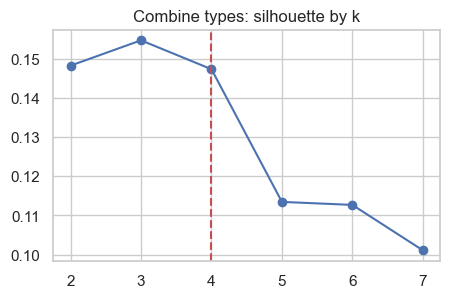

,size,speed,agility,explosive,n
cmb_type_id,,,,,
"explosive, undersized",-0.18,0.66,-0.14,0.67,47
"big/long, slower",0.90,-1.04,-0.30,-0.71,22
"agile, slower",0.66,-0.09,2.57,0.56,9
balanced (less explosive),-0.44,-0.18,-0.24,-0.55,38


,combine_height,combine_weight,arm_length,hand_size,forty,ten_yd_split,vertical,broad_jump,three_cone,short_shuttle,bench_reps
cmb_type,,,,,,,,,,,
"agile, slower",73.19,202.22,31.94,9.44,4.47,1.55,38.88,126.25,6.75,4.10,17.67
balanced (less explosive),71.53,191.74,30.67,9.01,4.51,1.54,34.11,120.90,7.09,4.28,16.27
"big/long, slower",73.38,205.95,32.19,9.45,4.60,1.57,33.42,120.20,7.04,4.33,16.30
"explosive, undersized",71.70,191.74,31.40,9.14,4.44,1.51,38.73,127.85,7.00,4.29,16.18



DBs with both types: 60 | agreement (ARI) between typologies = 0.036 (0 = independent)


cmb_type,"agile, slower",balanced (less explosive),"big/long, slower","explosive, undersized",All
trk_type,,,,,
deep safety · high depth,0,2,1,8,11
deep safety · low close_speed,0,2,6,2,10
press-man corner · high hs_per_rep,1,7,2,7,17
press-man corner · low width,2,2,0,6,10
slot DB,1,4,0,7,12
All,4,17,9,30,60


In [7]:
CF = [c for c in ["combine_height", "combine_weight", "arm_length", "hand_size", "forty", "ten_yd_split", "vertical",
                  "broad_jump", "three_cone", "short_shuttle", "bench_reps"] if c in db and db[c].notna().sum() >= 20]
db["n_skipped"] = db[[c for c in ["forty", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps"] if c in db]].isna().sum(axis=1)
Zc = db[CF].apply(lambda s: zs(s.fillna(s.median())))
comp = pd.DataFrame(index=db.index)
def _m(cols, sign=1):
    cols = [c for c in cols if c in Zc]; return sign * Zc[cols].mean(axis=1) if cols else np.nan
comp["size"] = _m(["combine_height", "combine_weight", "arm_length"]); comp["speed"] = _m(["forty", "ten_yd_split"], -1)
comp["agility"] = _m(["three_cone", "short_shuttle"], -1); comp["explosive"] = _m(["vertical", "broad_jump"])
comp = comp.dropna(axis=1, how="all")
ok = db[CF].notna().sum(axis=1) >= max(3, len(CF) // 2)          # need at least half the tests
km_c = KMeans(K_CMB, n_init=20, random_state=27).fit(Zc[ok])
sw = [(k, silhouette_score(Zc[ok], KMeans(k, n_init=10, random_state=27).fit_predict(Zc[ok]))) for k in range(2, 8)]
plt.figure(figsize=(5, 3)); plt.plot(*zip(*sw), "o-"); plt.axvline(K_CMB, color="r", ls="--"); plt.title("Combine types: silhouette by k"); plt.show()
db.loc[ok, "cmb_type_id"] = km_c.labels_
cc = comp[ok].groupby(db.loc[ok, "cmb_type_id"]).mean()
def name_cmb(r):
    hi, lo = r.idxmax(), r.idxmin()
    lbl = {"size": "big/long", "speed": "fast", "agility": "agile", "explosive": "explosive"}
    neg = {"size": "undersized", "speed": "slower", "agility": "stiff", "explosive": "less explosive"}
    return f"{lbl[hi]}, {neg[lo]}" if r[hi] > .25 else f"balanced ({neg[lo]})"
cnames = {i: name_cmb(cc.loc[i]) for i in cc.index}
for i, nm in list(cnames.items()):
    if list(cnames.values()).count(nm) > 1: cnames[i] = f"{nm} #{int(i)}"
db["cmb_type"] = db["cmb_type_id"].map(cnames)
display(cc.round(2).assign(n=db["cmb_type_id"].value_counts()).rename(index=cnames))
display(db.groupby("cmb_type")[CF].mean().round(2))

both = db.dropna(subset=["trk_type", "cmb_type"])
print(f"\nDBs with both types: {len(both)} | agreement (ARI) between typologies = {adjusted_rand_score(both['trk_type'], both['cmb_type']):.3f} (0 = independent)")
display(pd.crosstab(both["trk_type"], both["cmb_type"], margins=True))

## 6. The short shuttle, rebuilt from sensor data

The 5-10-5 is located in the Combine tracking (`drill_type == SHORT_SHUTTLE`). Each attempt is projected onto its main axis and split at the two direction reversals:

| feature | meaning |
|---|---|
| `sh_time` | sensor time, first movement → crossing back over the start line |
| `leg1/2/3` | the 5, 10 and 5 yard segments |
| `turn1_dwell`, `turn2_dwell` | time spent under 1.5 yd/s around each turn: how long he's "stuck" in the plant |
| `brake1/2` | peak deceleration into each turn |
| `reacc1/2` | peak re-acceleration out of each turn |
| `turn_asym` | \|dwell1 − dwell2\| ÷ mean. The two turns go opposite ways, so this is a **side-to-side** COD asymmetry. |
| `brake_asym` | the same, for braking into each turn |
| `cod_deficit` | shuttle time − his own sensor time to cover 20 yd in the 40. That's the time the turns *cost* him beyond his straight-line speed. |
| `dec_index` | mean braking ÷ mean re-acceleration (deceleration index) |

The sensor time is checked against the official `short_shuttle` first. Per player, the **best** attempt's times are used, and asymmetry is **averaged over attempts** so a single bad plant doesn't decide it.

**Resolution caveat:** the sensors record at 10 Hz, so a turn lasting a few tenths of a second is only a handful of frames. Turn dwell interpolates the speed-threshold crossings to soften this, but turn-level asymmetry is still noisy. Check its attempt-to-attempt reliability (printed below) before trusting any injury link.

DB drill types: {'SKILL_DRILLS_DB': 94623, 'FORTY_YARD_DASH': 9749, 'THREE_CONE_DRILL': 2301, 'SHORT_SHUTTLE': 1977}
shuttle attempts parsed: 29 (25 DBs) | 40 attempts: 195
sensor vs official shuttle: r = -0.05 (n=25), mean offset +0.27s


,sh_time,leg1,leg2,leg3,turn1_dwell,turn2_dwell,brake1,brake2,reacc1,reacc2,dec_index,sh_peak_speed,turn_asym,brake_asym,cod_deficit
count,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,25.000,20.000
mean,4.492,1.516,1.964,1.012,0.608,0.353,5.823,8.537,7.334,8.541,0.895,5.986,0.332,0.402,1.550
std,0.608,0.487,0.138,0.088,0.589,0.053,1.869,1.205,1.269,0.771,0.111,0.569,0.298,0.232,0.616
min,3.100,0.400,1.600,0.800,0.372,0.303,1.783,5.899,4.230,6.561,0.632,4.118,0.089,0.164,0.100
25%,4.500,1.400,1.900,1.000,0.384,0.324,6.153,8.104,6.959,8.078,0.883,5.964,0.181,0.244,1.475
50%,4.600,1.600,2.000,1.000,0.411,0.338,6.453,8.857,7.940,8.627,0.933,6.171,0.233,0.334,1.700
75%,4.800,1.800,2.000,1.100,0.457,0.356,6.950,9.373,8.144,9.042,0.959,6.239,0.309,0.408,1.900
max,5.900,2.600,2.300,1.200,3.255,0.511,7.536,10.299,8.651,9.569,1.034,6.696,1.457,1.050,2.800


Attempt-1 vs attempt-2 reliability (Spearman): {'sh_time': -0.8, 'turn1_dwell': -0.4, 'turn2_dwell': 0.8, 'turn_asym': -0.4, 'brake1': -0.4, 'brake2': -0.4, 'dec_index': -0.8}


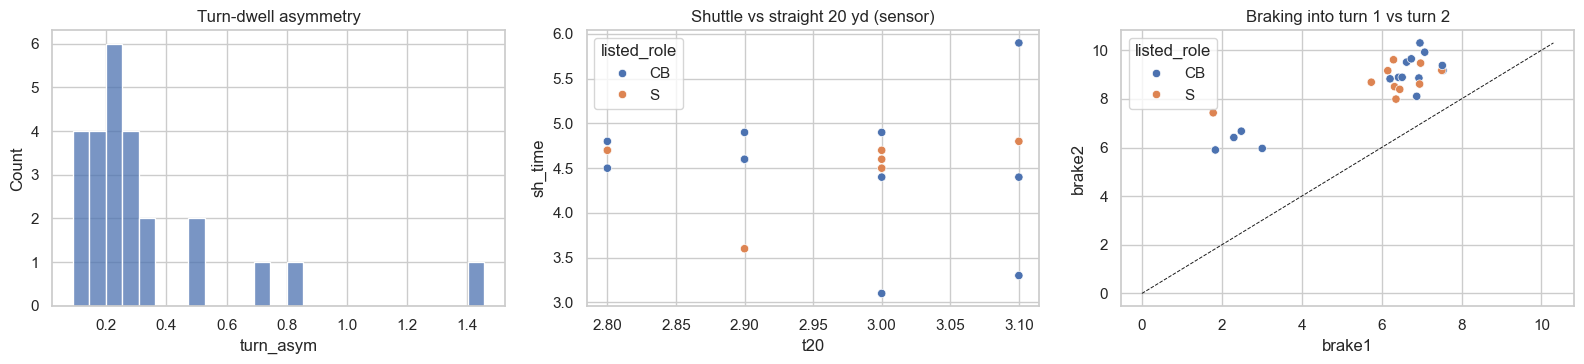

In [8]:
ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct = ct[ct["nfl_id"].isin(DB_IDS)].copy()
ct["time"] = pd.to_datetime(ct["time"], errors="coerce")
ct = ct.sort_values(["event_id", "nfl_id", "time"])
DT = pick(ct, ["drill_type"]); DN = pick(ct, ["drill_name"])
print("DB drill types:", ct[DT].value_counts().to_dict() if DT else "n/a")

def axis_motion(r):
    t = (r["time"] - r["time"].iloc[0]).dt.total_seconds().to_numpy()
    if len(t) < 10 or np.any(np.diff(t) <= 0): return None
    xy = np.c_[r["x"].to_numpy(float), r["y"].to_numpy(float)]
    ax_ = np.linalg.svd(xy - xy.mean(0), full_matrices=False)[2][0]
    pos = (xy - xy[0]) @ ax_
    v = np.gradient(pos, t); v = pd.Series(v).rolling(3, center=True, min_periods=1).mean().to_numpy()
    return t, pos, v

def shuttle_feats(r):
    out = axis_motion(r)
    if out is None: return None
    t, pos, v = out
    mv = np.flatnonzero(np.abs(v) > 0.5)
    if len(mv) < 5: return None
    i0 = mv[0]; t, pos, v = t[i0:] - t[i0], pos[i0:] - pos[i0], v[i0:]
    sv = np.sign(np.where(np.abs(v) < 0.3, 0, v))
    sp = np.abs(v)
    nz = np.flatnonzero(sv != 0)
    # each turn = slowest frame between the last frame moving one way and the first frame moving the other way
    flips = [nz[j - 1] + int(np.argmin(sp[nz[j - 1]:nz[j] + 1])) for j in range(1, len(nz)) if sv[nz[j]] != sv[nz[j - 1]]]
    if len(flips) < 2: return None
    k1, k2 = flips[0], flips[1]
    after = np.flatnonzero((np.arange(len(pos)) > k2) & (np.sign(pos) != np.sign(pos[k2])) )
    if len(after) == 0: return None
    kend = after[0]
    acc = np.gradient(sp, t)
    def dwell(k, thr=1.5):
        # time spent below thr yd/s around turn k, with linear interpolation of the crossings (10 Hz is coarse)
        if sp[k] >= thr: return 0.0
        lo, hi = k, k
        while lo > 0 and sp[lo] < thr: lo -= 1
        while hi < len(sp) - 1 and sp[hi] < thr: hi += 1
        def cross(i, j): return t[i] + (thr - sp[i]) * (t[j] - t[i]) / (sp[j] - sp[i]) if sp[j] != sp[i] else t[i]
        t_in = cross(lo, lo + 1) if sp[lo] >= thr else t[lo]
        t_out = cross(hi - 1, hi) if sp[hi] >= thr else t[hi]
        return max(t_out - t_in, 0.0)
    def win(k, a, b): return (t >= t[k] + a) & (t <= t[k] + b)
    br1, br2 = np.nanmax(-acc[win(k1, -1, 0)]), np.nanmax(-acc[win(k2, -1, 0)])
    ra1, ra2 = np.nanmax(acc[win(k1, 0, 1)]), np.nanmax(acc[win(k2, 0, 1)])
    d1, d2 = dwell(k1), dwell(k2)
    return {"sh_time": t[kend], "leg1": t[k1], "leg2": t[k2] - t[k1], "leg3": t[kend] - t[k2],
            "turn1_dwell": d1, "turn2_dwell": d2, "brake1": br1, "brake2": br2, "reacc1": ra1, "reacc2": ra2,
            "turn_asym": abs(d1 - d2) / ((d1 + d2) / 2) if d1 + d2 > 0 else np.nan,
            "brake_asym": abs(br1 - br2) / ((br1 + br2) / 2) if br1 + br2 > 0 else np.nan,
            "dec_index": ((br1 + br2) / 2) / ((ra1 + ra2) / 2) if ra1 + ra2 > 0 else np.nan,
            "sh_peak_speed": sp.max()}

def forty_feats(r):
    out = axis_motion(r)
    if out is None: return None
    t, pos, v = out
    mv = np.flatnonzero(np.abs(v) > 0.5)
    if len(mv) < 5: return None
    i0 = mv[0]; d = np.abs(pos[i0:] - pos[i0]); tt = t[i0:] - t[i0]
    return {"t20": tt[np.argmax(d >= 20)] if (d >= 20).any() else np.nan, "cmb_top_speed": r["s"].max()}

def drill_rows(mask, fn):
    rows = []
    for (ev, nid), r in ct[mask].groupby(["event_id", "nfl_id"], sort=False):
        q = fn(r.reset_index(drop=True))
        if q: rows.append({"event_id": ev, "nfl_id": nid, **q})
    return pd.DataFrame(rows)

dtype = ct[DT].astype(str).str.upper() if DT else pd.Series("", index=ct.index)
sh = drill_rows(dtype.str.contains("SHUTTLE"), shuttle_feats)
fo = drill_rows(dtype.str.contains("FORTY|40"), forty_feats)
print(f"shuttle attempts parsed: {len(sh)} ({sh['nfl_id'].nunique() if len(sh) else 0} DBs) | 40 attempts: {len(fo)}")

SH = ["sh_time", "leg1", "leg2", "leg3", "turn1_dwell", "turn2_dwell", "brake1", "brake2", "reacc1", "reacc2", "dec_index", "sh_peak_speed"]
if len(sh):
    best = sh.loc[sh.groupby("nfl_id")["sh_time"].idxmin()].set_index("nfl_id")[SH]
    asym = sh.groupby("nfl_id")[["turn_asym", "brake_asym"]].mean()
    shp = best.join(asym)
    if len(fo):
        f40 = fo.groupby("nfl_id").agg(t20=("t20", "min"), cmb_top_speed=("cmb_top_speed", "max"))
        shp = shp.join(f40, how="left"); shp["cod_deficit"] = shp["sh_time"] - shp["t20"]
    db = db.drop(columns=[c for c in shp if c in db]).merge(shp, left_on="nfl_id", right_index=True, how="left")
    if "short_shuttle" in db:
        dd = db[["short_shuttle", "sh_time"]].dropna()
        if len(dd) > 10:
            print(f"sensor vs official shuttle: r = {dd.corr().iloc[0, 1]:.2f} (n={len(dd)}), mean offset {(dd['sh_time'] - dd['short_shuttle']).mean():+.2f}s")
    SHF = [c for c in SH + ["turn_asym", "brake_asym", "cod_deficit"] if c in db]
    display(db[SHF].describe().round(3))
    two = sh.groupby("nfl_id").filter(lambda g: len(g) >= 2).sort_values("event_id").groupby("nfl_id").head(2)
    two["att"] = two.groupby("nfl_id").cumcount()
    rel = {f: two.pivot(index="nfl_id", columns="att", values=f).corr(method="spearman").iloc[0, 1]
           for f in ["sh_time", "turn1_dwell", "turn2_dwell", "turn_asym", "brake1", "brake2", "dec_index"] if f in two}
    print("Attempt-1 vs attempt-2 reliability (Spearman):", {k: round(v, 2) for k, v in rel.items()})
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    sns.histplot(db["turn_asym"].dropna(), bins=25, ax=axes[0]); axes[0].set_title("Turn-dwell asymmetry")
    if "cod_deficit" in db: sns.scatterplot(data=db, x="t20", y="sh_time", hue="listed_role", ax=axes[1]); axes[1].set_title("Shuttle vs straight 20 yd (sensor)")
    sns.scatterplot(data=db, x="brake1", y="brake2", hue="listed_role", ax=axes[2])
    mx = np.nanmax(db[["brake1", "brake2"]].to_numpy()) if db[["brake1", "brake2"]].notna().any().any() else 1
    axes[2].plot([0, mx], [0, mx], "k--", lw=.7)
    axes[2].set_title("Braking into turn 1 vs turn 2")
    plt.tight_layout(); plt.show()
else:
    SHF = []; print("No SHORT_SHUTTLE tracking found for DBs — §6–§8 shuttle parts will be skipped.")

In [9]:
# DB skill drills: lateral reversal quality (backpedal/T-step/W-type drills), as in earlier notebooks
def lateral_q(r):
    out = axis_motion(r)
    if out is None: return None
    t, pos, v = out
    vs = v[np.abs(v) > .3]
    if len(vs) < 4 or (np.diff(np.sign(vs)) != 0).sum() < 1: return None
    a_, b_ = v.max(), -v.min()
    return {"dbd_peak": max(a_, b_), "dbd_asym": abs(a_ - b_) / ((a_ + b_) / 2), "dbd_brake": np.nanmax(-np.gradient(v, t) * np.sign(v))}
dbd = drill_rows(dtype.str.contains("SKILL_DRILLS_DB|DB"), lateral_q)
if len(dbd):
    dbp = dbd.groupby("nfl_id")[["dbd_peak", "dbd_asym", "dbd_brake"]].mean()
    db = db.drop(columns=[c for c in dbp if c in db]).merge(dbp, left_on="nfl_id", right_index=True, how="left")
    print(f"DB skill-drill attempts with reversals: {len(dbd)} ({dbd['nfl_id'].nunique()} DBs)")
DBD = [c for c in ["dbd_peak", "dbd_asym", "dbd_brake"] if c in db]

DB skill-drill attempts with reversals: 742 (122 DBs)


## 7. Game-level speed, injury status, and "speed in coverage" after injury

Per player-game: p90 peak speed, closing speed with the ball in the air, high-speed seconds per rep, and p90 braking. Each is compared to his own rolling baseline (same approach as the get-off notebook). Then:
- **Playing while listed**: is he slower in coverage when he suits up with a lower-body or hamstring listing?
- **Return from injury**: in his first 3 games back after a lower-body onset, how do speed and closing compare with his last 3 healthy games, and what about snaps?
- **Speed reserve**: in-game p95 speed ÷ his Combine top speed. Hamstring strains cluster near maximal sprinting, so players who routinely run near their ceiling may be more exposed.

In [10]:
gl = rep.groupby(["game_id", "nfl_id"]).agg(trk_reps=("play_id", "size"), speed_p90=("peak_speed", lambda s: s.quantile(.9)),
                                            speed_p95=("peak_speed", lambda s: s.quantile(.95)),
                                            close_speed=("close_speed", "median"), hs_per_rep=("hs_s", "mean"),
                                            brake_p90=("peak_decel", lambda s: s.quantile(.9))).reset_index()
gl = gl[gl["trk_reps"] >= 8]
panel = panel.drop(columns=[c for c in gl if c in panel and c not in ["game_id", "nfl_id"]]).merge(gl, on=["game_id", "nfl_id"], how="left")
panel = panel.sort_values(["nfl_id", "season", "team_game_no"]).reset_index(drop=True)
GM = ["speed_p90", "close_speed", "hs_per_rep", "brake_p90"]
for m in GM:
    v = panel[m]; mu = v.groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).mean())
    panel[f"dev_{m}"] = v - mu
panel["listed_lower"] = (panel["lower"] & panel["played"]).astype(float)
panel["listed_ham"] = (panel["hamstring"] & panel["played"]).astype(float)
panel["listed_other"] = (panel["is_injury"] & ~panel["lower"] & panel["played"]).astype(float)
pm = panel[panel["played"]]
for m in GM:
    fit(f"dev_{m}", ["listed_lower", "listed_other"], pm, f"Playing while listed → {m} (vs own baseline)")
fit("dev_speed_p90", ["listed_ham", "listed_other"], pm, "Playing with a HAMSTRING listing → peak speed")

# Speed reserve (player level)
if "cmb_top_speed" in db:
    res_ = panel.groupby("nfl_id")["speed_p95"].median()
    db["speed_reserve"] = db["nfl_id"].map(res_) / db["cmb_top_speed"]
    print("Median in-game p95 speed as share of Combine top speed:", round(db["speed_reserve"].median(), 3))


Playing while listed → speed_p90 (vs own baseline) | MixedLM (lbfgs) | n=1,125, players=69


,coef,ci_lo,ci_hi,p
Intercept,0.003,-2036111.816,2036111.822,1.000
listed_lower,-0.034,-0.144,0.075,0.538
listed_other,0.044,-0.079,0.168,0.481



Playing while listed → close_speed (vs own baseline) | MixedLM (lbfgs) | n=1,123, players=69


,coef,ci_lo,ci_hi,p
Intercept,-0.016,-2722650.123,2722650.091,1.000
listed_lower,-0.096,-0.245,0.052,0.203
listed_other,-0.083,-0.251,0.084,0.330



Playing while listed → hs_per_rep (vs own baseline) | MixedLM (lbfgs) | n=1,125, players=69


,coef,ci_lo,ci_hi,p
Intercept,-0.002,-506946.695,506946.691,1.000
listed_lower,-0.004,-0.031,0.023,0.783
listed_other,0.010,-0.021,0.040,0.544



Playing while listed → brake_p90 (vs own baseline) | MixedLM (lbfgs) | n=1,125, players=69


,coef,ci_lo,ci_hi,p
Intercept,-0.010,-2896282.662,2896282.642,1.000
listed_lower,-0.107,-0.263,0.049,0.179
listed_other,-0.124,-0.300,0.052,0.166



Playing with a HAMSTRING listing → peak speed | MixedLM (lbfgs) | n=1,125, players=69


,coef,ci_lo,ci_hi,p
Intercept,0.003,-0.027,0.033,0.845
listed_ham,-0.055,-0.384,0.275,0.746
listed_other,0.047,-0.075,0.169,0.448


Median in-game p95 speed as share of Combine top speed: 0.732


In [11]:
# Return-to-play after LOWER-BODY onsets: speed/closing/snaps, last 3 healthy games vs first 3 back
pt = panel[panel["played"]].sort_values(["nfl_id", "season", "team_game_no"])
rows = []
for _, o in panel[panel["onset_lower"]].iterrows():
    mine = pt[pt["nfl_id"] == o["nfl_id"]]
    before = mine[(mine["season"] < o["season"]) | ((mine["season"] == o["season"]) & (mine["team_game_no"] < o["team_game_no"]))].tail(4).iloc[:-1]
    after = mine[(mine["season"] == o["season"]) & (mine["team_game_no"] >= o["team_game_no"])].head(3)
    if len(before) < 2 or len(after) < 2: continue
    r = {"nfl_id": o["nfl_id"], "hamstring": bool(o["onset_ham"])}
    for m in GM + ["snaps"]: r[f"chg_{m}"] = after[m].median() - before[m].median()
    rows.append(r)
ret = pd.DataFrame(rows).merge(db[["nfl_id", "trk_type", "cmb_type"]], on="nfl_id", how="left")
print(f"lower-body onsets with before/after games: {len(ret)}")
if len(ret):
    tab = [{"group": g, "metric": m, **dict(zip(["mean", "lo", "hi", "n"], cluster_boot_mean(d[m], d["nfl_id"])))}
           for g, d in [("all lower-body", ret), ("hamstring", ret[ret["hamstring"]])] for m in [f"chg_{x}" for x in GM + ["snaps"]]]
    display(pd.DataFrame(tab).round(3))

lower-body onsets with before/after games: 85


,group,metric,mean,lo,hi,n
0,all lower-body,chg_speed_p90,-0.026,-0.135,0.076,82
1,all lower-body,chg_close_speed,0.011,-0.116,0.143,82
2,all lower-body,chg_hs_per_rep,-0.005,-0.028,0.019,82
3,all lower-body,chg_brake_p90,-0.102,-0.281,0.060,82
4,all lower-body,chg_snaps,-1.829,-5.520,1.677,85
5,hamstring,chg_speed_p90,-0.203,-0.680,0.073,11
6,hamstring,chg_close_speed,-0.083,-0.405,0.203,11
7,hamstring,chg_hs_per_rep,-0.040,-0.118,0.020,11
8,hamstring,chg_brake_p90,0.323,-0.002,0.644,11
9,hamstring,chg_snaps,-5.091,-18.505,8.602,11


## 8. Tying types and shuttle traits to injury and cost

For each **tracking type** and each **Combine type**:
- injury onsets per 100 games played (all, lower-body, hamstring), with exact Poisson CIs
- absences, snaps per team game, coverage EPA on the field, and speed change after return
- a **Poisson model with draft pick and exposure**: do the types add anything beyond pick? (likelihood-ratio test vs. pick only)

Then the **shuttle screen**: for every shuttle feature, the rate ratio per 1 SD for each injury outcome (pick-adjusted Poisson), plus correlations with usage and return-to-play speed loss. Opt-outs are included.

In [12]:
def type_table(col):
    d = db.dropna(subset=[col]).copy(); d = d[d["games"].fillna(0) > 0]
    rows = []
    for tname, g in d.groupby(col):
        r = {"type": tname, "players": len(g), "games": int(g["games"].sum())}
        for e in ["onsets", "onsets_lower", "onsets_ham"]:
            rate, lo, hi = poisson_rate(g[e].sum(), g["games"].sum()); r[f"{e}/100"] = f"{rate:.1f} [{lo:.1f}, {hi:.1f}]"
        r["absences/100"] = round(100 * g["absences"].sum() / g["games"].sum(), 1)
        r["snaps/team game"] = round(g["snaps_per_team_game"].mean(), 1)
        if "epa_on_field" in g: r["EPA on field"] = round(g["epa_on_field"].mean(), 3)
        if len(ret): r["Δ speed after lower-body (yd/s)"] = round(ret.loc[ret[col] == tname, "chg_speed_p90"].mean(), 3)
        rows.append(r)
    display(pd.DataFrame(rows).set_index("type"))
    for e in ["onsets", "onsets_lower", "onsets_ham"]:
        dd = d[[e, "games", "log_pick", col]].dropna()
        if dd[e].sum() < 5: continue
        try:
            base = smf.poisson(f"{e} ~ log_pick", dd, offset=np.log(dd["games"])).fit(disp=0)
            full = smf.poisson(f"{e} ~ log_pick + C({col})", dd, offset=np.log(dd["games"])).fit(disp=0)
            lr = 2 * (full.llf - base.llf); dfree = full.df_model - base.df_model
            print(f"  {e}: does {col} add beyond pick? LR={lr:.2f}, df={dfree:.0f}, p={stats.chi2.sf(lr, dfree):.3f}")
        except Exception as ex: print(f"  {e}: model failed ({ex})")

print("=== Tracking types ==="); type_table("trk_type")
print("\n=== Combine types ==="); type_table("cmb_type")

=== Tracking types ===


,players,games,onsets/100,onsets_lower/100,onsets_ham/100,absences/100,snaps/team game,EPA on field,Δ speed after lower-body (yd/s)
type,,,,,,,,,
deep safety · high depth,11,253,"8.7 [5.4, 13.2]","5.5 [3.0, 9.3]","2.8 [1.1, 5.7]",6.3,37.8,-0.056,0.055
deep safety · low close_speed,12,318,"9.1 [6.1, 13.1]","3.8 [1.9, 6.6]","0.9 [0.2, 2.8]",5.7,31.0,-0.006,0.096
press-man corner · high hs_per_rep,18,438,"10.5 [7.7, 14.0]","6.2 [4.1, 9.0]","0.5 [0.1, 1.6]",7.1,35.2,-0.030,0.117
press-man corner · low width,10,227,"12.8 [8.6, 18.3]","8.4 [5.0, 13.1]","2.2 [0.7, 5.1]",13.2,29.4,-0.004,-0.046
slot DB,12,335,"13.1 [9.5, 17.6]","8.1 [5.3, 11.7]","0.3 [0.0, 1.7]",8.1,29.9,-0.032,-0.094


  onsets: does trk_type add beyond pick? LR=4.78, df=4, p=0.311
  onsets_lower: does trk_type add beyond pick? LR=6.94, df=4, p=0.139
  onsets_ham: does trk_type add beyond pick? LR=12.11, df=4, p=0.017

=== Combine types ===


,players,games,onsets/100,onsets_lower/100,onsets_ham/100,absences/100,snaps/team game,EPA on field,Δ speed after lower-body (yd/s)
type,,,,,,,,,
"agile, slower",6,93,"16.1 [9.0, 26.6]","11.8 [5.9, 21.2]","0.0 [0.0, 4.0]",9.7,24.2,-0.120,-0.121
balanced (less explosive),30,419,"9.3 [6.6, 12.7]","6.4 [4.2, 9.4]","1.2 [0.4, 2.8]",11.5,17.7,0.007,0.127
"big/long, slower",14,271,"9.6 [6.3, 14.1]","5.5 [3.1, 9.1]","1.8 [0.6, 4.3]",6.6,20.1,-0.037,-0.168
"explosive, undersized",41,884,"11.8 [9.6, 14.3]","6.8 [5.2, 8.7]","1.2 [0.6, 2.2]",7.6,30.3,-0.026,-0.030


  onsets: does cmb_type add beyond pick? LR=3.90, df=3, p=0.272
  onsets_lower: does cmb_type add beyond pick? LR=3.50, df=3, p=0.321
  onsets_ham: does cmb_type add beyond pick? LR=2.70, df=3, p=0.440


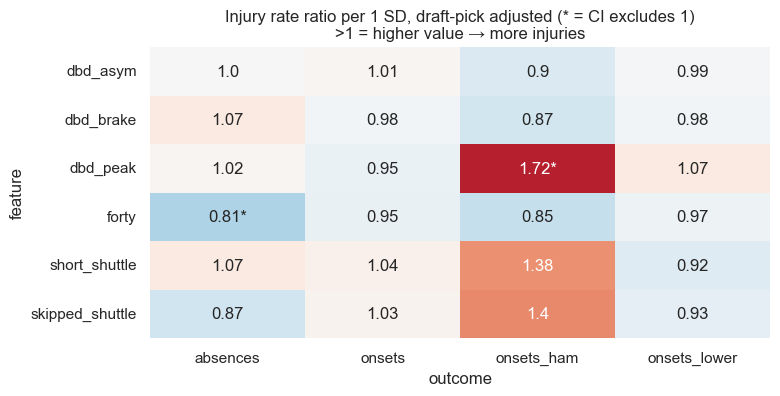

,feature,outcome,RR_per_SD,lo,hi,events,n,CI excludes 1
23,forty,absences,0.807,0.656,0.992,129.0,83,True
28,skipped_shuttle,absences,0.870,0.614,1.232,149.0,96,False
8,dbd_asym,absences,1.000,0.840,1.192,149.0,96,False
3,dbd_peak,absences,1.015,0.879,1.172,149.0,96,False
18,short_shuttle,absences,1.067,0.783,1.453,49.0,23,False
13,dbd_brake,absences,1.068,0.909,1.254,149.0,96,False
20,forty,onsets,0.949,0.792,1.138,164.0,83,False
0,dbd_peak,onsets,0.954,0.844,1.079,195.0,96,False
10,dbd_brake,onsets,0.976,0.850,1.120,195.0,96,False
5,dbd_asym,onsets,1.013,0.872,1.177,195.0,96,False


Shuttle traits vs speed change after lower-body injury:


,feature,ρ with Δ peak speed,ρ with Δ closing speed,n
0,sh_time,0.24,-0.30,17
1,leg1,0.25,-0.34,17
2,leg2,0.08,-0.12,17
3,leg3,0.06,-0.37,17
4,turn1_dwell,-0.18,0.17,17
5,turn2_dwell,-0.49,0.02,17
6,brake1,0.27,-0.23,17
7,brake2,0.37,-0.35,17
8,reacc1,0.24,-0.09,17
9,reacc2,0.27,0.20,17


In [13]:
# Shuttle (and other Combine-tracking) screen: pick-adjusted Poisson rate ratio per SD
SCREEN = SHF + DBD + [c for c in ["short_shuttle", "three_cone", "forty", "speed_reserve"] if c in db]
d = db[db["games"].fillna(0) > 0].copy()
d["skipped_shuttle"] = d["short_shuttle"].isna().astype(float) if "short_shuttle" in d else np.nan
rows = []
for f in SCREEN + ["skipped_shuttle"]:
    if f not in d or d[f].notna().sum() < 20 or d[f].std() == 0: continue
    x = d[f] if f == "skipped_shuttle" else zs(d[f])
    for e in ["onsets", "onsets_lower", "onsets_ham", "absences"]:
        dd = pd.DataFrame({"y": d[e], "x": x, "lp": d["log_pick"], "g": d["games"]}).dropna()
        if dd["y"].sum() < 5: continue
        try:
            r = smf.poisson("y ~ x + lp", dd, offset=np.log(dd["g"])).fit(disp=0)
            ci = r.conf_int().loc["x"]
            rows.append({"feature": f, "outcome": e, "RR_per_SD": np.exp(r.params["x"]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]),
                         "events": int(dd["y"].sum()), "n": len(dd)})
        except Exception: pass
    rr = stats.spearmanr(d[f], d["snaps_per_team_game"], nan_policy="omit")[0]
    rows.append({"feature": f, "outcome": "ρ with snaps/team game", "RR_per_SD": rr, "n": d[[f, "snaps_per_team_game"]].dropna().shape[0]})
scr = pd.DataFrame(rows)
scr["CI excludes 1"] = (scr["lo"] > 1) | (scr["hi"] < 1)
heat = scr[scr["outcome"] != "ρ with snaps/team game"].pivot(index="feature", columns="outcome", values="RR_per_SD")
sig = scr[scr["outcome"] != "ρ with snaps/team game"].pivot(index="feature", columns="outcome", values="CI excludes 1")
plt.figure(figsize=(8, 0.38 * len(heat) + 1.5))
sns.heatmap(np.log(heat), annot=heat.round(2).astype(str) + np.where(sig.fillna(False), "*", ""), fmt="", cmap="RdBu_r", center=0, vmin=-.7, vmax=.7, cbar=False)
plt.title("Injury rate ratio per 1 SD, draft-pick adjusted (* = CI excludes 1)\n>1 = higher value → more injuries"); plt.show()
display(scr.sort_values(["outcome", "RR_per_SD"]).round(3))

# Do shuttle traits relate to speed lost after a lower-body injury?
if len(ret) and SHF:
    rr = ret.merge(db[["nfl_id"] + SHF], on="nfl_id")
    out = []
    for f in SHF:
        dd = rr[[f, "chg_speed_p90", "chg_close_speed"]].dropna()
        if len(dd) >= 10:
            out.append({"feature": f, "ρ with Δ peak speed": stats.spearmanr(dd[f], dd["chg_speed_p90"])[0],
                        "ρ with Δ closing speed": stats.spearmanr(dd[f], dd["chg_close_speed"])[0], "n": len(dd)})
    if out: print("Shuttle traits vs speed change after lower-body injury:"); display(pd.DataFrame(out).round(2))

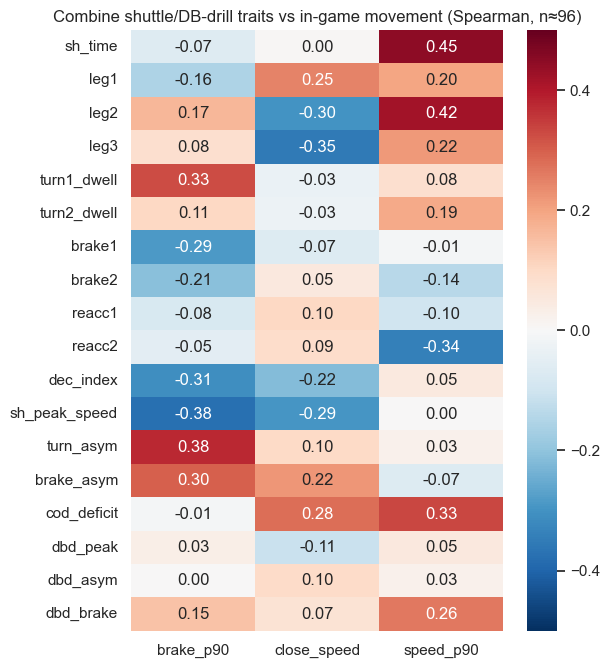

In [14]:
# Does the shuttle actually transfer to the field? Shuttle braking/turns vs in-game braking and closing (player level)
if SHF:
    fld = panel[panel["played"]].groupby("nfl_id")[["brake_p90", "close_speed", "speed_p90"]].median()
    tf = db.set_index("nfl_id")[SHF + DBD].join(fld, how="inner")
    cr = tf.corr(method="spearman").loc[SHF + DBD, ["brake_p90", "close_speed", "speed_p90"]]
    plt.figure(figsize=(6, 0.35 * len(cr) + 1.5))
    sns.heatmap(cr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.5, vmax=.5)
    plt.title(f"Combine shuttle/DB-drill traits vs in-game movement (Spearman, n≈{len(tf)})"); plt.show()

## 9. From injury tendencies to scouting drills

The table below turns this run's results into evidence for or against each proposed drill. A proposal is marked **supported** when the matching result has a confidence interval that excludes "no effect". Otherwise it's **not supported by this data**, and you should say so.

| # | Proposed drill / measurement | Injury tendency it targets | Evidence row(s) checked |
|---|---|---|---|
| 1 | **Bilateral 505 with COD deficit**: two timed 180° turns per side, minus the 10-yd time. Report the deficit per side and the asymmetry. | Side-to-side change-of-direction asymmetry → lower-body injury | shuttle `turn_asym`, `brake_asym` |
| 2 | **Sensor-scored shuttle (zero cost)**: report turn dwell, braking and re-acceleration per turn from the existing tracking, not just total time | Same as 1, using data the Combine already collects | `turn1/2_dwell`, `brake1/2`, `dec_index` |
| 3 | **Deceleration test**: 20-yd sprint into a 3-yd stop box, scoring peak braking and stopping distance | Braking capacity → knee, ankle and hamstring loading | `brake*`, `dec_index`, in-game `brake_p90` transfer |
| 4 | **Flying-10 and repeated sprints** (e.g. 6×30 yd, 30 s rest): top speed and percentage drop-off | High-speed exposure and running near max speed → hamstring | `speed_reserve`, `onsets_ham` by type, `hs_per_rep` types |
| 5 | **Backpedal-to-break (T-step / W) scored per side**: break time and braking each way | DB-specific asymmetry the shuttle can't see | `dbd_asym`, `dbd_brake` |
| 6 | **COD deficit relative to the 40**, not raw shuttle time | Fast players who lose a lot in turns. Raw shuttle time rewards straight-line speed. | `cod_deficit` |

The 3-cone and 40 are already run. The proposals are about **scoring what's already measured differently** (1, 2, 6) and adding **two short tests** (3, 4) aimed at the injury mechanisms common to DBs.

In [15]:
def evid(features, outcomes=("onsets_lower", "onsets_ham", "onsets")):
    s = scr[scr["feature"].isin(features) & scr["outcome"].isin(outcomes)]
    if s.empty: return "no data", ""
    hits = s[s["CI excludes 1"] == True]
    best = (s.assign(dist=np.abs(np.log(s["RR_per_SD"]))).sort_values("dist", ascending=False).iloc[0])
    detail = f"{best['feature']} → {best['outcome']}: RR {best['RR_per_SD']:.2f} [{best['lo']:.2f}, {best['hi']:.2f}], {int(best['events'])} events"
    return ("SUPPORTED" if len(hits) else "not supported by this data"), detail

proposals = [
    ("1 Bilateral 505 + COD deficit", ["turn_asym", "brake_asym"]),
    ("2 Sensor-scored shuttle turns", ["turn1_dwell", "turn2_dwell", "brake1", "brake2", "reacc1", "reacc2", "dec_index"]),
    ("3 Deceleration test", ["brake1", "brake2", "dec_index", "dbd_brake"]),
    ("4 Flying-10 + repeated sprint", ["speed_reserve", "forty"]),
    ("5 Backpedal-to-break per side", ["dbd_asym", "dbd_brake", "dbd_peak"]),
    ("6 COD deficit vs 40", ["cod_deficit"]),
]
rows = [{"proposal": p, "status": evid(f)[0], "strongest evidence": evid(f)[1]} for p, f in proposals]
display(pd.DataFrame(rows))

,proposal,status,strongest evidence
0,1 Bilateral 505 + COD deficit,no data,
1,2 Sensor-scored shuttle turns,no data,
2,3 Deceleration test,not supported by this data,"dbd_brake → onsets_ham: RR 0.87 [0.57, 1.34], ..."
3,4 Flying-10 + repeated sprint,not supported by this data,"forty → onsets_ham: RR 0.85 [0.50, 1.43], 20 e..."
4,5 Backpedal-to-break per side,SUPPORTED,"dbd_peak → onsets_ham: RR 1.72 [1.09, 2.72], 2..."
5,6 COD deficit vs 40,no data,


## 10. Synthesis and save

In [16]:
print("Tracking types:", db["trk_type"].value_counts().to_dict())
print("Combine types:", db["cmb_type"].value_counts().to_dict())
top = scr[(scr["outcome"] != "ρ with snaps/team game") & scr["CI excludes 1"]].sort_values("RR_per_SD")
print(f"\nInjury associations with CIs excluding 1 ({len(top)} of {int((scr['outcome'] != 'ρ with snaps/team game').sum())} tested; "
      f"~{0.05 * (scr['outcome'] != 'ρ with snaps/team game').sum():.1f} expected by chance):")
display(top.round(3))
db.to_csv("db_types_shuttle_outcomes.csv", index=False)
panel.to_csv("db_player_game_panel.csv", index=False)
if len(sh): sh.to_csv("db_shuttle_attempts.csv", index=False)
print("Saved db_types_shuttle_outcomes.csv, db_player_game_panel.csv, db_shuttle_attempts.csv")

Tracking types: {'press-man corner · high hs_per_rep': 18, 'slot DB': 12, 'deep safety · low close_speed': 12, 'deep safety · high depth': 11, 'press-man corner · low width': 10}
Combine types: {'explosive, undersized': 47, 'balanced (less explosive)': 38, 'big/long, slower': 22, 'agile, slower': 9}

Injury associations with CIs excluding 1 (2 of 24 tested; ~1.2 expected by chance):


,feature,outcome,RR_per_SD,lo,hi,events,n,CI excludes 1
23,forty,absences,0.807,0.656,0.992,129.0,83,True
2,dbd_peak,onsets_ham,1.719,1.086,2.723,21.0,96,True


Saved db_types_shuttle_outcomes.csv, db_player_game_panel.csv, db_shuttle_attempts.csv


### Reading this honestly
- **Count events before believing a rate.** Hamstring onsets among ~170 DBs will be few. A type with 3 hamstring strains can look alarming by chance.
- **Many features are tested.** The synthesis prints how many associations would clear the bar by chance alone. One starred cell is a lead, not a finding. Look for agreement: a shuttle trait that relates to lower-body injuries, *and* transfers to in-game braking, *and* predicts speed loss after return.
- **The two typologies answer different questions.** Tracking types describe a role, which teams choose. Combine types describe an athlete, which is known before the draft. Only Combine-type findings can inform draft-day scouting directly. Tracking-type findings speak to in-season load management.